<a href="https://colab.research.google.com/github/A-KOStov/Evlash-Valeria-2253/blob/main/Task5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Задача 1** Катер с разряжающейся батареей

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [2]:
t = sp.Symbol('t', positive=True)
m, k, P0, tau = sp.symbols('m k P0 tau', positive=True)
v = sp.Function('v')(t)

In [3]:
ode = sp.Eq(v.diff(t) + (k/m)*v - (P0/m)*sp.exp(-t/tau)*v**(-1), 0)
solution = sp.dsolve(ode, v)
sp.pprint(solution)

⎡       ⎧           _________________________________________                  ↪
⎢       ⎪          ╱                                  2⋅k⋅t                    ↪
⎢       ⎪         ╱                                   ─────    -k⋅t            ↪
⎢       ⎪        ╱                                      m      ─────           ↪
⎢       ⎪       ╱    2⋅C₁⋅k⋅τ      C₁⋅m       2⋅P₀⋅τ⋅ℯ           m             ↪
⎢       ⎪-     ╱     ───────── - ───────── + ─────────────── ⋅ℯ       for k ≠  ↪
⎢       ⎪     ╱      2⋅k⋅τ - m   2⋅k⋅τ - m          t      t                   ↪
⎢       ⎪    ╱                                      ─      ─                   ↪
⎢v(t) = ⎨   ╱                                       τ      τ                   ↪
⎢       ⎪ ╲╱                                 2⋅k⋅τ⋅ℯ  - m⋅ℯ                    ↪
⎢       ⎪                                                                      ↪
⎢       ⎪                                    -k⋅t                              ↪
⎢       ⎪                   

In [4]:
m_val = 1.0
k_val = 0.5
P0_val = 10.0
v0_val = 0.1

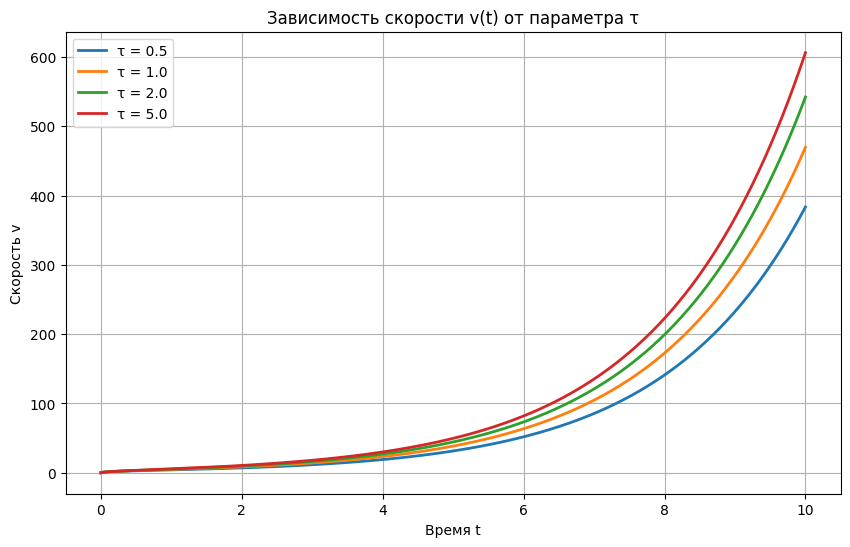

In [5]:
def dv_dt(t, v, tau_val):
    return (P0_val / m_val) * np.exp(-t / tau_val) / v + (k_val / m_val) * v

tau_values = [0.5, 1.0, 2.0, 5.0]
t_span = (0, 10)
t_eval = np.linspace(0, 10, 500)

plt.figure(figsize=(10, 6))

for tau_val in tau_values:
    sol = solve_ivp(dv_dt, t_span, [v0_val], args=(tau_val,), t_eval=t_eval, method='RK45')
    plt.plot(sol.t, sol.y[0], label=f'τ = {tau_val}', linewidth=2)

plt.title('Зависимость скорости v(t) от параметра τ')
plt.xlabel('Время t')
plt.ylabel('Скорость v')
plt.grid(True)
plt.legend()
plt.show()